In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
# labels for data
cols = ["age", "workclass", "fnlwgt", "education", "education-num",
        "marital-status", "occupation", "relationship", "race", "sex",
        "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"]
# adds labels via name=cols param
data = pd.read_csv("../adult/adult.data", names=cols, skipinitialspace=True)

In [29]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education-num   32561 non-null  int64
 5   marital-status  32561 non-null  str  
 6   occupation      30718 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital-gain    32561 non-null  int64
 11  capital-loss    32561 non-null  int64
 12  hours-per-week  32561 non-null  int64
 13  native-country  31978 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [3]:
data.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [31]:
data.nunique()

age                  73
workclass             9
fnlwgt            21648
education            16
education-num        16
marital-status        7
occupation           15
relationship          6
race                  5
sex                   2
capital-gain        119
capital-loss         92
hours-per-week       94
native-country       42
income                2
dtype: int64

it looks like capital-gain and capital-loss is noise maybe consider dropping those

Use case (made up): classify if a person will make more than 50k a year
# Things to do
- make 2 plots for age with income more and less than 50k
- make difference plot for workclass, relationship, marital status, native country 
- make age categorical plots (?)

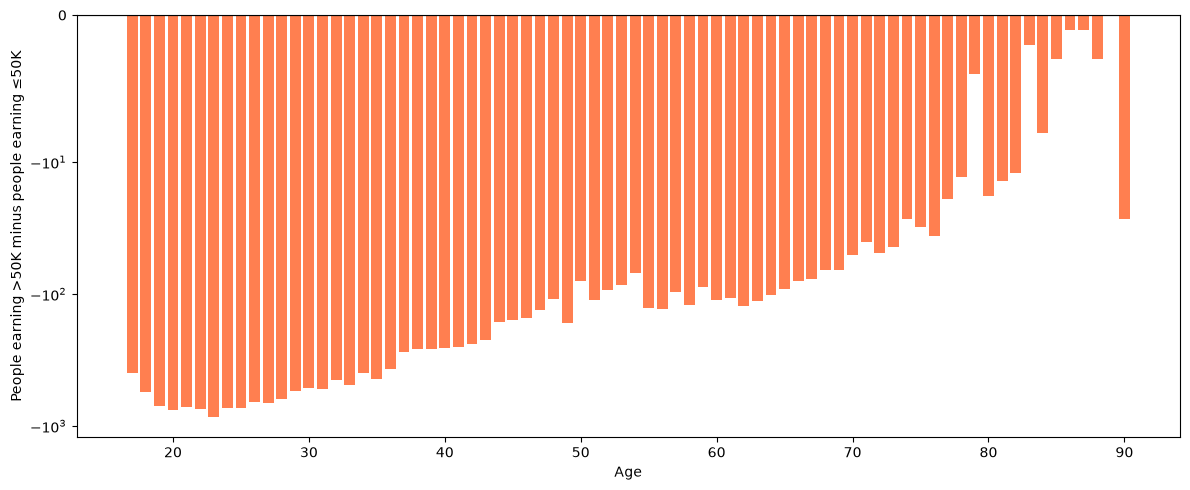

In [24]:
counts = pd.crosstab(data["age"], data["income"])
difference = counts[">50K"] - counts["<=50K"]

colors = ["steelblue" if value >= 0 else "coral" for value in difference]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(difference.index, difference.values, color=colors)
ax.set_yscale("symlog", linthresh=10)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Age")
ax.set_ylabel("People earning >50K minus people earning ≤50K")

plt.tight_layout()
plt.show()

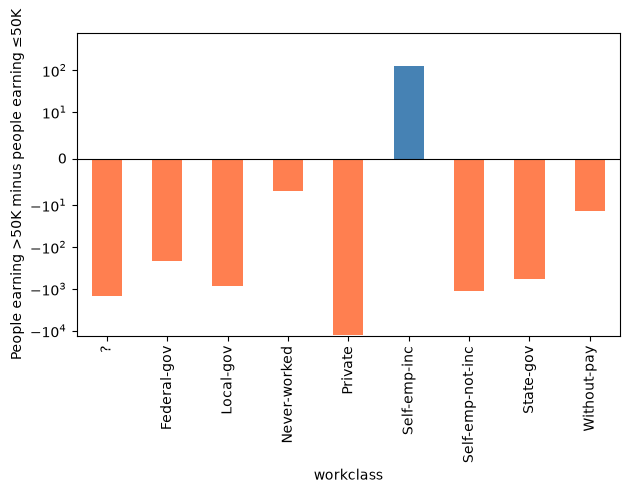

In [14]:
counts = pd.crosstab(data["workclass"], data["income"])
difference = counts[">50K"] - counts["<=50K"]

colors = ["steelblue" if value >= 0 else "coral" for value in difference]
ax = difference.plot.bar(color=colors)
ax.set_yscale("symlog", linthresh=10)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("People earning >50K minus people earning ≤50K")

plt.tight_layout()
plt.show()


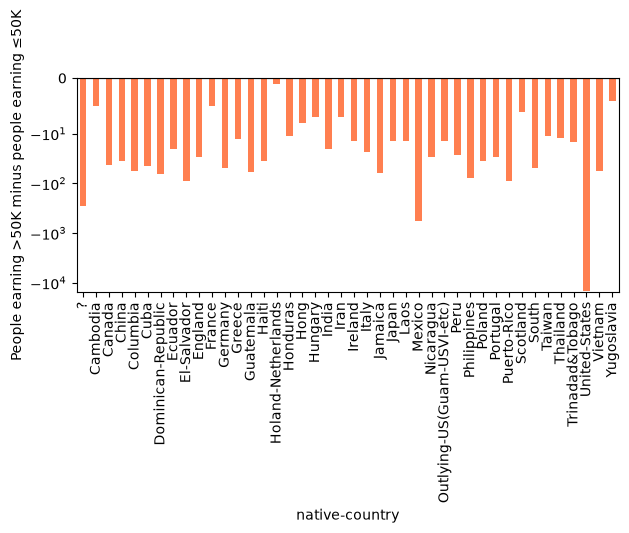

In [13]:
counts = pd.crosstab(data["native-country"], data["income"])
difference = counts[">50K"] - counts["<=50K"]

colors = ["steelblue" if value >= 0 else "coral" for value in difference]

ax = difference.plot.bar(color=colors)
ax.set_yscale("symlog", linthresh=10)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("People earning >50K minus people earning ≤50K")

plt.tight_layout()
plt.show()


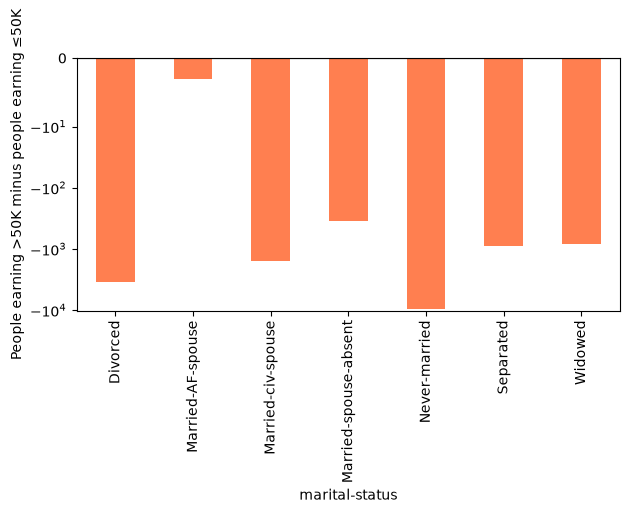

In [18]:
counts = pd.crosstab(data["marital-status"], data["income"])
difference = counts[">50K"] - counts["<=50K"]

colors = ["steelblue" if value >= 0 else "coral" for value in difference]

ax = difference.plot.bar(color=colors)
ax.set_yscale("symlog", linthresh=10)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("People earning >50K minus people earning ≤50K")

plt.tight_layout()
plt.show()

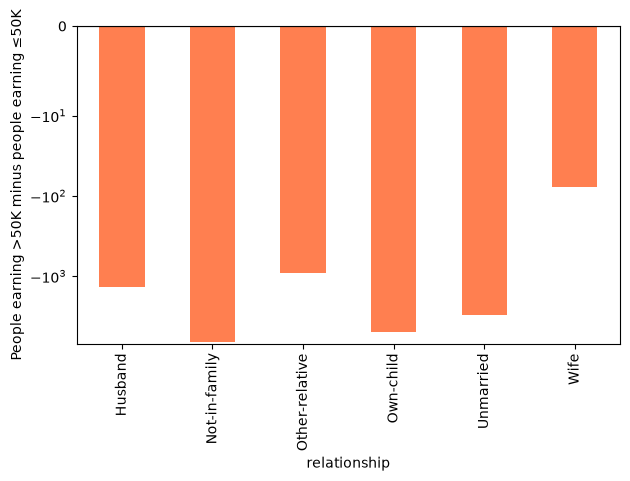

In [17]:
counts = pd.crosstab(data["relationship"], data["income"])
difference = counts[">50K"] - counts["<=50K"]

colors = ["steelblue" if value >= 0 else "coral" for value in difference]

ax = difference.plot.bar(color=colors)
ax.set_yscale("symlog", linthresh=10)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("People earning >50K minus people earning ≤50K")

plt.tight_layout()
plt.show()

In [6]:
missing_workclass = data['workclass'] == "?"
data[missing_workclass].shape[0]

1836

In [7]:
education_LUT = data[['education','education-num']].drop_duplicates()
education_LUT = education_LUT.sort_values("education-num").reset_index(drop=True)
education_LUT

,education,education-num
0,Preschool,1
1,1st-4th,2
2,5th-6th,3
3,7th-8th,4
4,9th,5
5,10th,6
6,11th,7
7,12th,8
8,HS-grad,9
9,Some-college,10


- Education-num digunakan untuk mengubah nilai kategori `education` menjadi angka
- Terdapat 15 kategori `education`

In [8]:
for col in cols:
    missing = data[col] == "?"
    print(f"Amount of rows with missing {col}: {missing.sum()}")

total_rows = data[cols].eq("?").any(axis=1).sum()
print("Total rows with missing value:", total_rows)

Amount of rows with missing age: 0
Amount of rows with missing workclass: 1836
Amount of rows with missing fnlwgt: 0
Amount of rows with missing education: 0
Amount of rows with missing education-num: 0
Amount of rows with missing marital-status: 0
Amount of rows with missing occupation: 1843
Amount of rows with missing relationship: 0
Amount of rows with missing race: 0
Amount of rows with missing sex: 0
Amount of rows with missing capital-gain: 0
Amount of rows with missing capital-loss: 0
Amount of rows with missing hours-per-week: 0
Amount of rows with missing native-country: 583
Amount of rows with missing income: 0
Total rows with missing value: 2399


In [58]:
display(data["age"].unique())

array([39, 50, 38, 53, 28, 37, 49, 52, 31, 42, 30, 23, 32, 40, 34, 25, 43,
       54, 35, 59, 56, 19, 20, 45, 22, 48, 21, 24, 57, 44, 41, 29, 18, 47,
       46, 36, 79, 27, 67, 33, 76, 17, 55, 61, 70, 64, 71, 68, 66, 51, 58,
       26, 60, 90, 75, 65, 77, 62, 63, 80, 72, 74, 69, 73, 81, 78, 88, 82,
       83, 84, 85, 86, 87])

In [59]:
skip_cols ={"capital-gain","fnlwgt","capital-loss","education-num", "hours-per-week","age"}
for col in cols:
    if col in skip_cols:
        continue

    counts = data[col].value_counts(dropna=False)
    display(counts)

age_ranges = [(20, 30), (31, 40),(41, 50), (51, 65), (66, 80), (81, 100)]

for lower, upper in age_ranges:
    count = data["age"].between(lower, upper).sum()
    print(f"{lower}-{upper}: {count}")

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
?                    1836
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

education
HS-grad         10501
Some-college     7291
Bachelors        5355
Masters          1723
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           646
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           333
1st-4th           168
Preschool          51
Name: count, dtype: int64

marital-status
Married-civ-spouse       14976
Never-married            10683
Divorced                  4443
Separated                 1025
Widowed                    993
Married-spouse-absent      418
Married-AF-spouse           23
Name: count, dtype: int64

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
?                    1843
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64

relationship
Husband           13193
Not-in-family      8305
Own-child          5068
Unmarried          3446
Wife               1568
Other-relative      981
Name: count, dtype: int64

race
White                 27816
Black                  3124
Asian-Pac-Islander     1039
Amer-Indian-Eskimo      311
Other                   271
Name: count, dtype: int64

sex
Male      21790
Female    10771
Name: count, dtype: int64

native-country
United-States                 29170
Mexico                          643
?                               583
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Guatemala                        64
Japan                            62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
France       

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

20-30: 8915
31-40: 8546
41-50: 6983
51-65: 5302
66-80: 1059
81-100: 99


In [9]:
from pprint import pprint
for col in ['workclass','education','marital-status','relationship','race','sex','native-country']:
    values = data[col].unique().tolist()
    print(f"{col} ({len(values)} unique values):")
    pprint(values, width=80, compact=True)
    print()


workclass (9 unique values):
['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov', 'Local-gov', '?',
 'Self-emp-inc', 'Without-pay', 'Never-worked']

education (16 unique values):
['Bachelors', 'HS-grad', '11th', 'Masters', '9th', 'Some-college', 'Assoc-acdm',
 'Assoc-voc', '7th-8th', 'Doctorate', 'Prof-school', '5th-6th', '10th',
 '1st-4th', 'Preschool', '12th']

marital-status (7 unique values):
['Never-married', 'Married-civ-spouse', 'Divorced', 'Married-spouse-absent',
 'Separated', 'Married-AF-spouse', 'Widowed']

relationship (6 unique values):
['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried', 'Other-relative']

race (5 unique values):
['White', 'Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo', 'Other']

sex (2 unique values):
['Male', 'Female']

native-country (42 unique values):
['United-States', 'Cuba', 'Jamaica', 'India', '?', 'Mexico', 'South',
 'Puerto-Rico', 'Honduras', 'England', 'Canada', 'Germany', 'Iran',
 'Philippines', 'Italy', 'Poland', 'Columb